### Step 1.1: Import Required Libraries

In this step, we import the Python libraries required for data loading, manipulation, preprocessing, and machine learning.

- Pandas and NumPy are used for data manipulation.
- Scikit-learn provides tools for data preprocessing and model development.
- Path is used to locate the dataset file.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("Libraries imported successfully!")

Libraries imported successfully!


### Step 1.2: Load the Dataset

In this step, we load the Student Performance Factors dataset using Pandas.

The `Path` library helps locate the CSV file in Kaggle's input directory. After loading the dataset, we display its dimensions and first five rows to understand its structure.

In [2]:
# Locate the dataset file
csv_files = list(Path("/kaggle/input").rglob("StudentPerformanceFactors.csv"))

if not csv_files:
    raise FileNotFoundError("Dataset not found. Please attach it first.")

# Load the dataset
df = pd.read_csv(csv_files[0])

# Display dataset information
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


### Step 1.3: Check Missing Values and Duplicate Rows

Before preprocessing the dataset, we need to identify missing values and duplicate records.

- Missing values can affect model training and need to be handled appropriately.
- Duplicate rows may introduce repeated information and affect model performance.

We use Pandas functions to inspect missing values in each column and count duplicate rows.

In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64

Duplicate Rows:
0


### Step 1.4: Create the Target Variable and Engineer Features

In this step, we create a categorical target variable named `Needs_Support` using the `Exam_Score` column.

Students with an exam score below 65 are assigned class 1 (Needs Support), while students with a score of 65 or above are assigned class 0 (No Support).

We also create two additional features to represent relationships between existing variables:

- **Study_Attendance_Interaction:** Combines study hours and attendance.
- **Study_Sleep_Ratio:** Represents the relationship between study hours and sleep hours.

These engineered features may help the machine learning models identify useful patterns in student performance.

In [5]:
# Create the categorical target variable
df["Needs_Support"] = (df["Exam_Score"] < 65).astype(int)

# Create additional features
df["Study_Attendance_Interaction"] = (
    df["Hours_Studied"] * df["Attendance"] / 100
)

df["Study_Sleep_Ratio"] = (
    df["Hours_Studied"] / df["Sleep_Hours"]
)

# Display target distribution
print("Target Distribution:")
print(df["Needs_Support"].value_counts().sort_index())

print("\nTarget Percentages:")
print(
    df["Needs_Support"].value_counts(normalize=True).sort_index() * 100
)

Target Distribution:
Needs_Support
0    5155
1    1452
Name: count, dtype: int64

Target Percentages:
Needs_Support
0    78.023309
1    21.976691
Name: proportion, dtype: float64


### Step 1.5: Separate Features and Target Variable

In this step, we separate the independent features (X) from the dependent target variable (y).

- **X:** Contains the input features used by the machine learning models.
- **y:** Contains the `Needs_Support` target variable that the models will predict.

We remove `Exam_Score` from the input features because it was used to create the target variable. Including it would cause data leakage and give the models information about the answer.

In [6]:
# Separate features and target variable
X = df.drop(columns=["Exam_Score", "Needs_Support"])
y = df["Needs_Support"]

# Display shapes
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (6607, 21)
Target Shape: (6607,)


### Step 1.6: Split the Dataset into Training and Testing Sets

In this step, we divide the dataset into training and testing sets.

- **80% Training Data:** Used to train models, compare their performance, and tune hyperparameters.
- **20% Testing Data:** Reserved for the final evaluation of the selected model.

We use `stratify=y` to maintain the same class distribution in both sets. We also set `random_state=42` to ensure reproducibility.

The test set will remain untouched until Step 6, as required by the assignment.

In [8]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display training data information
print("Training Features Shape:", X_train.shape)
print("Training Target Shape:", y_train.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts().sort_index())

Training Features Shape: (5285, 21)
Training Target Shape: (5285,)

Training Class Distribution:
Needs_Support
0    4124
1    1161
Name: count, dtype: int64


### Step 1.7: Define the Preprocessing Pipeline

In this step, we prepare the preprocessing pipeline to handle missing values and categorical features.

We divide the input features into two groups:

1. **Numerical Features:**
   - Missing values are replaced using the median strategy.

2. **Categorical Features:**
   - Missing values are replaced using the most frequent value.
   - Categorical values are converted into numerical form using One-Hot Encoding.

We use `ColumnTransformer` to apply the appropriate preprocessing techniques to each feature group.

The preprocessing pipeline will be fitted during cross-validation through the model pipelines. This prevents data leakage between training and validation folds.

In [10]:
# Identify numerical and categorical features
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# Preprocessing for numerical features
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocessing for categorical features
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Display feature information
print("Number of Numerical Features:", len(numeric_features))
print("Number of Categorical Features:", len(categorical_features))

print("\nPreprocessing pipeline created successfully!")

Number of Numerical Features: 8
Number of Categorical Features: 13

Preprocessing pipeline created successfully!


### Task 2: Compare Four Models Using 5-Fold Cross-Validation

In this task, we compare four classification models using 5-fold cross-validation on the training data.

The models include KNN, Decision Tree, Random Forest, and Gradient Boosting. We evaluate them using the mean and standard deviation of their cross-validation scores.

In [11]:
# Import machine learning models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Import cross-validation function
from sklearn.model_selection import cross_val_score

print("Machine learning models imported successfully!")

Machine learning models imported successfully!


### Step 2.2: Create Model Pipelines

In this step, we create pipelines for all four classification models. Each pipeline includes the required preprocessing steps followed by the model.

StandardScaler is specifically applied to KNN because it is distance-based.

In [12]:
# KNN pipeline with feature scaling
knn_pipeline = make_pipeline(
    preprocessor,
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Decision Tree pipeline
dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

# Random Forest pipeline
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

# Gradient Boosting pipeline
gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(random_state=42))
])

print("All four model pipelines created successfully!")

All four model pipelines created successfully!


### Step 2.3: Evaluate Models Using 5-Fold Cross-Validation

We evaluate all four models using 5-fold cross-validation on the training data. We calculate the mean and standard deviation of accuracy scores to compare their performance and consistency.

In [13]:
# Store all four models
models = {
    "KNN": knn_pipeline,
    "Decision Tree": dt_pipeline,
    "Random Forest": rf_pipeline,
    "Gradient Boosting": gb_pipeline
}

# Perform 5-fold cross-validation
cv_results = {}

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    cv_results[name] = {
        "Mean CV Score": scores.mean(),
        "Standard Deviation": scores.std()
    }

# Display comparison table
results_df = pd.DataFrame(cv_results).T

display(results_df.round(4))

,Mean CV Score,Standard Deviation
KNN,0.8375,0.0026
Decision Tree,0.8715,0.0101
Random Forest,0.9145,0.0056
Gradient Boosting,0.9429,0.0033


### Task 3: Hyperparameter Tuning

In this task, we tune KNN and Decision Tree models to find the hyperparameters that provide the best cross-validation performance.


### Step 3.1: KNN Hyperparameter Tuning

We evaluate KNN using different odd values of K, ranging from 1 to 15. We use 5-fold cross-validation to calculate the mean accuracy for each value and identify the best K.


In [14]:
# Define odd K values
k_values = list(range(1, 16, 2))

knn_cv_scores = []

# Evaluate each K value using 5-fold cross-validation
for k in k_values:

    knn_model = make_pipeline(
        preprocessor,
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_val_score(
        knn_model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    knn_cv_scores.append(scores.mean())

# Create comparison table
knn_tuning_df = pd.DataFrame({
    "K Value": k_values,
    "Mean CV Accuracy": knn_cv_scores
})

display(knn_tuning_df.round(4))

# Identify best K
best_k = k_values[np.argmax(knn_cv_scores)]

print("Best K:", best_k)
print("Best CV Accuracy:", round(max(knn_cv_scores), 4))

,K Value,Mean CV Accuracy
0,1,0.7907
1,3,0.8206
2,5,0.8375
3,7,0.8407
4,9,0.8412
5,11,0.8401
6,13,0.8375
7,15,0.8358


Best K: 9
Best CV Accuracy: 0.8412


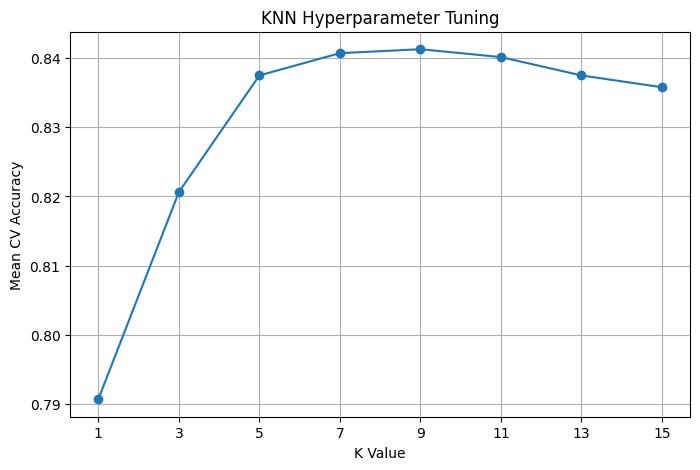

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    knn_cv_scores,
    marker="o"
)

plt.xlabel("K Value")
plt.ylabel("Mean CV Accuracy")
plt.title("KNN Hyperparameter Tuning")
plt.xticks(k_values)
plt.grid(True)

plt.show()

### Step 3.2: Decision Tree Hyperparameter Tuning

We evaluate the Decision Tree model using different maximum depth values: 2, 3, 5, 10, and None. We use 5-fold cross-validation to identify the depth that achieves the highest mean accuracy.

In [16]:
# Define maximum depth values
depth_values = [2, 3, 5, 10, None]

dt_cv_scores = []

# Evaluate each depth using 5-fold cross-validation
for depth in depth_values:

    dt_model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])

    scores = cross_val_score(
        dt_model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    dt_cv_scores.append(scores.mean())

# Create comparison table
dt_tuning_df = pd.DataFrame({
    "Max Depth": depth_values,
    "Mean CV Accuracy": dt_cv_scores
})

display(dt_tuning_df.round(4))

# Identify best depth
best_depth = depth_values[np.argmax(dt_cv_scores)]

print("Best Max Depth:", best_depth)
print("Best CV Accuracy:", round(max(dt_cv_scores), 4))

,Max Depth,Mean CV Accuracy
0,2.0,0.8643
1,3.0,0.8643
2,5.0,0.8738
3,10.0,0.8744
4,NaN,0.8715


Best Max Depth: 10
Best CV Accuracy: 0.8744


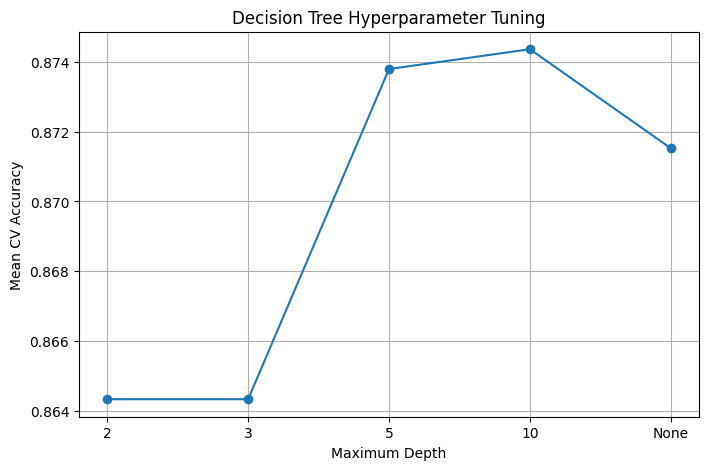

In [18]:
plt.figure(figsize=(8, 5))

depth_labels = ["2", "3", "5", "10", "None"]

plt.plot(
    depth_labels,
    dt_cv_scores,
    marker="o"
)

plt.xlabel("Maximum Depth")
plt.ylabel("Mean CV Accuracy")
plt.title("Decision Tree Hyperparameter Tuning")
plt.grid(True)

plt.show()

### Task 4: Random Forest Hyperparameter Tuning

In this task, we use GridSearchCV to find the best Random Forest hyperparameters by testing different values of `n_estimators` and `max_depth` with 5-fold cross-validation.

In [19]:
from sklearn.model_selection import GridSearchCV

# Define hyperparameter grid
rf_param_grid = {
    "model__n_estimators": [50, 100, 200],
    "model__max_depth": [3, 5, None]
}

# Initialize GridSearchCV
rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

print("Random Forest GridSearchCV initialized successfully!")

Random Forest GridSearchCV initialized successfully!


### Step 4.2: Find the Best Random Forest Parameters

We fit GridSearchCV on the training data to evaluate all hyperparameter combinations and identify the combination with the highest mean cross-validation accuracy.

In [20]:
# Perform grid search
rf_grid_search.fit(X_train, y_train)

# Display best results
print("Best Parameters:")
print(rf_grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(round(rf_grid_search.best_score_, 4))

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best Parameters:
{'model__max_depth': None, 'model__n_estimators': 200}

Best Cross-Validation Accuracy:
0.9177


### Step 5: Gradient Boosting Hyperparameter Tuning

We use GridSearchCV to find the best Gradient Boosting hyperparameters by testing different values of `n_estimators` and `learning_rate` with 5-fold cross-validation.

In [22]:
# Define hyperparameter grid
gb_param_grid = {
    "model__n_estimators": [50, 100, 200],
    "model__learning_rate": [0.01, 0.05, 0.1, 0.2]
}

# Initialize GridSearchCV
gb_grid_search = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=gb_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

print("Gradient Boosting GridSearchCV initialized successfully!")

Gradient Boosting GridSearchCV initialized successfully!


### Step 5.2: Find the Best Gradient Boosting Parameters

We fit GridSearchCV on the training data to evaluate all hyperparameter combinations and identify the best-performing configuration.

In [23]:
# Perform grid search
gb_grid_search.fit(X_train, y_train)

# Display best results
print("Best Parameters:")
print(gb_grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(round(gb_grid_search.best_score_, 4))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters:
{'model__learning_rate': 0.2, 'model__n_estimators': 200}

Best Cross-Validation Accuracy:
0.9552


### Check Overfitting

In this step, we compare the training accuracy with cross-validation accuracy of the tuned models. The difference between these scores helps us identify overfitting and evaluate model generalization.

In [24]:
# Create the best tuned KNN model
best_knn_model = make_pipeline(
    preprocessor,
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=best_k)
)

# Create the best tuned Decision Tree model
best_dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=best_depth,
        random_state=42
    ))
])

# Store the best tuned models
tuned_models = {
    "KNN": best_knn_model,
    "Decision Tree": best_dt_model,
    "Random Forest": rf_grid_search.best_estimator_,
    "Gradient Boosting": gb_grid_search.best_estimator_
}

# Store their best cross-validation scores
best_cv_scores = {
    "KNN": max(knn_cv_scores),
    "Decision Tree": max(dt_cv_scores),
    "Random Forest": rf_grid_search.best_score_,
    "Gradient Boosting": gb_grid_search.best_score_
}

# Calculate training scores and generalization gaps
overfitting_results = []

for name, model in tuned_models.items():

    model.fit(X_train, y_train)

    train_score = model.score(X_train, y_train)
    cv_score = best_cv_scores[name]

    overfitting_results.append({
        "Model": name,
        "Training Score": train_score,
        "CV Score": cv_score,
        "Gap": train_score - cv_score
    })

# Display results
overfitting_df = pd.DataFrame(overfitting_results)

display(overfitting_df.round(4))

,Model,Training Score,CV Score,Gap
0,KNN,0.8806,0.8412,0.0394
1,Decision Tree,0.9826,0.8744,0.1082
2,Random Forest,1.0000,0.9177,0.0823
3,Gradient Boosting,0.9951,0.9552,0.0399


### Task 6: Final Test Evaluation and Model Selection

In this step, we evaluate the best-performing tuned model using the reserved test dataset.

Based on cross-validation results, Gradient Boosting achieved the highest accuracy. We evaluate it using accuracy, confusion matrix, and classification report.

In [25]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Select the best tuned model
best_model = gb_grid_search.best_estimator_

# Make predictions on the test set (once)
y_pred = best_model.predict(X_test)

# Calculate accuracy
test_accuracy = accuracy_score(y_test, y_pred)

print("Best Model: Gradient Boosting")
print("Test Accuracy:", round(test_accuracy, 4))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Display classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Support", "Needs Support"]
))

Best Model: Gradient Boosting
Test Accuracy: 0.9523

Confusion Matrix:
[[1016   15]
 [  48  243]]

Classification Report:
               precision    recall  f1-score   support

   No Support       0.95      0.99      0.97      1031
Needs Support       0.94      0.84      0.89       291

     accuracy                           0.95      1322
    macro avg       0.95      0.91      0.93      1322
 weighted avg       0.95      0.95      0.95      1322



### Step 6.2: Final Model Selection

Gradient Boosting was selected as the final model because it achieved the highest cross-validation accuracy of 95.52% among the four models.

On the test dataset, it achieved an accuracy of 95.23%, with a precision of 94% and recall of 84% for the Needs Support class.

Recall is particularly important for this task because identifying students who may need support is a priority. Overall, Gradient Boosting provided the best performance among the evaluated models.